# 1D First-Order Wave / Advection Equation: Upwind Scheme

## 1. Theory & CFL Stability Analysis
The 1D advection equation is:
$$\frac{\partial \psi}{\partial t} + c \frac{\partial \psi}{\partial x} = 0$$

**Directional Upwind Discretization:**
- For $c > 0$: $\psi_i^{n+1} = \psi_i^n - k (\psi_i^n - \psi_{i-1}^n)$, where $k = \frac{c \Delta t}{\Delta x}$.
- For $c < 0$: $\psi_i^{n+1} = \psi_i^n - k (\psi_{i+1}^n - \psi_i^n)$.

**Courant-Friedrichs-Lewy (CFL) Condition:**
$$\mathbf{k = \frac{c \Delta t}{\Delta x} \le 1 \implies c \le \frac{\Delta x}{\Delta t}}$$

**Numerical Diffusion:**
$$D_{\text{num}} = \frac{c \Delta x}{2}(1 - k)$$
When $k = 1$, $D_{\text{num}} = 0$, giving the exact translation with zero dissipation.

## 2. EXACT CODE FROM QUIZ 2 REFERENCE PDF (Section 3.1)
1st-Order Advection Wave with upwind scheme, periodic boundary conditions, exact analytical solution comparison, and space-time trajectory heatmap.

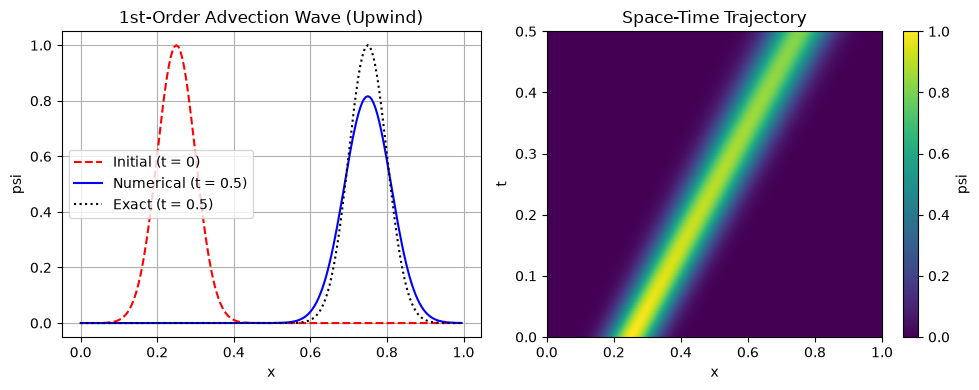

In [2]:
import numpy as np 
import matplotlib.pyplot as plt

# Parameters
N = 200
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
v = 1.0                 # Wave propagation speed c
k = 0.5                 # Courant number CFL = v*dt/dx (Must satisfy 0 <= k <= 1)
dt = k * dx / v
t_end = 0.5
nt = int(round(t_end / dt))

# Initial Conditions: Gaussian wave packet
psi = np.exp(-200 * (x - 0.25)**2)
psi_0 = psi.copy()
psi_T = [psi.copy()]

# Exact analytical translation on periodic domain
def exact(x, t):
    return np.exp(-200 * ((x - v * t) - 0.25)**2)

# Time integration using Upwind Scheme (Periodic Boundary Conditions)
for n in range(nt):
    psi_new = np.zeros(N)
    for i in range(1, N):
        psi_new[i] = psi[i] - k * (psi[i] - psi[i-1])
        
    # Periodic boundary wrap-around at x = 0
    psi_new[0] = psi[0] - k * (psi[0] - psi[-1])
    
    psi = psi_new
    psi_T.append(psi.copy())

# Plotting Comparison and Space-Time Heatmap
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, psi_0, 'r--', label='Initial (t = 0)')
plt.plot(x, psi, 'b-', label=f'Numerical (t = {t_end})')
plt.plot(x, exact(x, t_end), 'k:', label=f'Exact (t = {t_end})')
plt.xlabel('x'); plt.ylabel('psi'); plt.title('1st-Order Advection Wave (Upwind)')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
psi_T = np.array(psi_T)
plt.imshow(psi_T, aspect='auto', origin='lower', extent=[0, L, 0, t_end])
plt.colorbar(label='psi')
plt.xlabel('x'); plt.ylabel('t')
plt.title('Space-Time Trajectory')
plt.tight_layout()
plt.show()

## 3. PROFESSOR'S IN-CLASS CODE (from `n+1/1storderwaveeqn.ipynb`)
This is the code as directly written in the practice notebook `n+1/1storderwaveeqn.ipynb`.

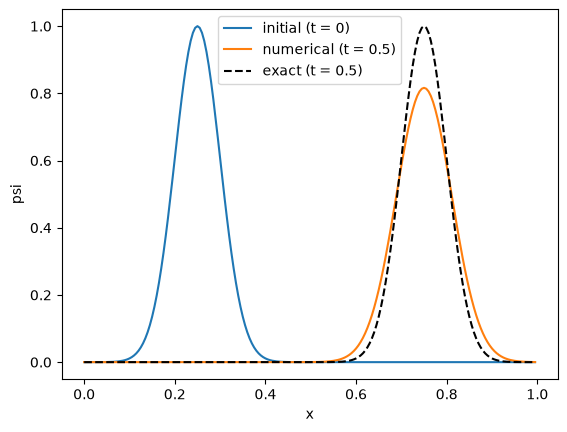

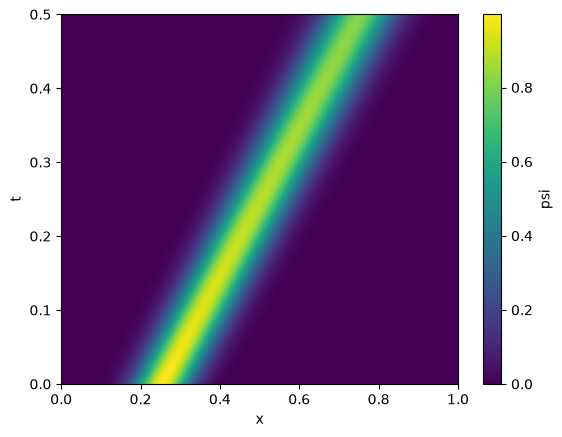

In [4]:
import numpy as np 
import matplotlib.pyplot as plt

# Parameters
N = 200
L = 1.0
dx = L / N
x = np.linspace(0, L, N, endpoint=False)
v = 1.0                 # wave speed
k = 0.5                 # CFL number, v*dt/dx (must satisfy 0 <= k <= 1)
dt = k * dx / v
t_end = 0.5
nt = int(round(t_end / dt))

# Initial Conditions
psi = np.exp(-200 * (x - 0.25)**2)
psi_0 = psi.copy()
psi_T = []

# Exact solution: the initial profile simply translates by v*t
def exact(x, t):
    return np.exp(-200 * (((x - v*t) % L) - 0.25)**2)

# Time integration with the upwind scheme (periodic boundary conditions)
for n in range(nt):
    psi_new = np.zeros(N)
    for i in range(1, N):
        psi_new[i] = psi[i] - k*(psi[i] - psi[i-1])
    # Periodic wrap-around at the left boundary
    psi_new[0] = psi[0] - k*(psi[0] - psi[-1])
    psi = psi_new
    psi_T.append(psi.copy())

plt.plot(x, psi_0, label='initial (t = 0)')
plt.plot(x, psi, label=f'numerical (t = {t_end})')
plt.plot(x, exact(x, t_end), 'k--', label=f'exact (t = {t_end})')
plt.xlabel('x')
plt.ylabel('psi')
plt.legend()
plt.show()

# Space-time evolution of the pulse
psi_T = np.array(psi_T)
plt.imshow(psi_T, aspect='auto', origin='lower',
           extent=[0, L, 0, t_end], cmap='viridis')
plt.colorbar(label='psi')
plt.xlabel('x')
plt.ylabel('t')
plt.show()

## 4. Diagnostics: Why Central Difference in Space Fails
Central space FTCS yields $|G|^2 = 1 + k^2 \sin^2(\kappa \Delta x) > 1$, which is unconditionally unstable.

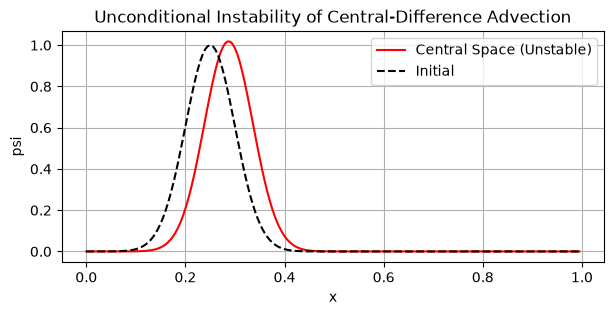

In [5]:
# Testing Central Difference in Space
psi_central = psi_0.copy()
for _ in range(15):
    psi_central = psi_central - (k / 2.0) * (np.roll(psi_central, -1) - np.roll(psi_central, 1))

plt.figure(figsize=(7, 3))
plt.plot(x, psi_central, 'r-', label='Central Space (Unstable)')
plt.plot(x, psi_0, 'k--', label='Initial')
plt.title('Unconditional Instability of Central-Difference Advection')
plt.xlabel('x'); plt.ylabel('psi'); plt.legend(); plt.grid(True); plt.show()